### Basic Network Stats

In [40]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import random
import matplotlib.colors as colors
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import powerlaw

from convokit import Corpus, download

In [41]:
corpus = Corpus(filename=download("conversations-gone-awry-corpus"))
corpus.print_summary_stats()


# Get convo df
convo_db = corpus.get_attribute_table("conversation", ["conversation_has_personal_attack", "page_title", "page_id", "pair_id", "conversation_has_personal_attack", "verified", "pair_verified", "annotation_year"])
convo_db.reset_index(inplace=True)

# Get utter df
utter_df = corpus.get_utterances_dataframe()

# Merge them to get speakers
full_utter = pd.merge(utter_df, convo_db, left_on='conversation_id', right_on='id', how='outer')

# And add speakers column to convo_db
convo_db['speakers'] = [[] for _ in range(len(convo_db))]

# Now loop through and give speakers to conversation db
for index, row in full_utter.iterrows():
    conversation_id = row["conversation_id"]
    if not row["speaker"] in convo_db.loc[convo_db['id'] == conversation_id]["speakers"].iloc[0]:
        convo_db.loc[convo_db['id'] == conversation_id]["speakers"].iloc[0].append(row["speaker"])

# Now get speakers df
speakers = corpus.get_speakers_dataframe()


Dataset already exists at /Users/caseygilbert/.convokit/saved-corpora/conversations-gone-awry-corpus
Number of Speakers: 8069
Number of Utterances: 30021
Number of Conversations: 4188


In [42]:

# Build our bipartite network
wiki_graph = nx.Graph()
speaker_list = []
conversation_list = []

for index in speakers.iterrows():
    speaker_list.append(index[0])
    
wiki_graph.add_nodes_from(speaker_list, bipartite=0, node_type="speaker")

for row, index in convo_db.iterrows():
    conversation_list.append(index["id"])
    wiki_graph.add_node(index["id"], bipartite=1, node_type="conversation", conversation_has_personal_attack=index["conversation_has_personal_attack"], page_title=index["page_title"], page_id=index["page_id"], pair_id=index["pair_id"], verified=index["verified"], pair_verified=index["pair_verified"], annotation_year=index["annotation_year"])
    for speaker in index["speakers"]:
        wiki_graph.add_edge(speaker, index["id"], is_personal_attack=index["conversation_has_personal_attack"])
        if (index["conversation_has_personal_attack"] == True):
            wiki_graph.nodes[speaker]['personal_attacks'] =  wiki_graph.nodes[speaker].get('personal_attacks',0) + 1

# Now get normalized attack values
for node in wiki_graph.nodes:
    if wiki_graph.nodes[node]['bipartite'] == 0:
        total = wiki_graph.nodes[node].get('personal_attacks',0)
        total_degs = wiki_graph.degree[node]
        wiki_graph.nodes[node]['personal_attack_normed'] = total/total_degs



In [127]:
# Build projected network with links

import itertools

speaker_list = []
for index in speakers.iterrows():
    speaker_list.append(index[0])
    
wiki_projected = nx.Graph()   
wiki_projected.add_nodes_from(speaker_list)

# Add edges based on conversation
for node, attr in wiki_graph.nodes(data=True):
    if (attr['bipartite'] == 1):
        # get his links
        edges = wiki_graph.edges(node)
        speakers_in_convo = []
        for edge in edges:
            speakers_in_convo.append(edge[1])
        speaker_edges = itertools.combinations(speakers_in_convo, 2)

        # Add attacks to links
        has_personal_attack = False
        if wiki_graph.nodes[node].get('conversation_has_personal_attack',0) == True:
            has_personal_attack = True

            for speaker in speakers_in_convo:
                wiki_projected.nodes[speaker]['personal_attacks'] =  wiki_projected.nodes[speaker].get('personal_attacks',0) + 1

        wiki_projected.add_edges_from(speaker_edges, has_personal_attack=has_personal_attack)



# Now get normalized attack values
for node in wiki_projected.nodes:
    total = wiki_projected.nodes[node].get('personal_attacks',0)
    total_degs = wiki_projected.degree[node]
    if total_degs > 0:
        wiki_projected.nodes[node]['personal_attack_normed'] = total/total_degs
    else:
        wiki_projected.nodes[node]['personal_attack_normed'] = 0


In [128]:
# Check our projected network

speakers_nodes = {n for n, d in wiki_graph.nodes(data=True) if d["bipartite"] == 0}
projected_graph = nx.bipartite.projected_graph(wiki_graph, speakers_nodes)

nodes = list(wiki_projected.nodes)
nodes.sort()

p_nodes = list(projected_graph.nodes)
p_nodes.sort()

if not nodes == p_nodes:
    print("Nodes are different!!")
# nodes are the same 
# edges?

edges = list(wiki_projected.edges)
edges.sort()

p_edges = list(projected_graph.edges)
p_edges.sort()

if not len(p_edges) == len(edges):
    print("Edge counts are different!!")

for i, edge in enumerate(edges):
    if edge not in p_edges and (edge[1], edge[0]) not in p_edges:
        print(f"An extra edge in our projected! {edge}")

for i, edge in enumerate(p_edges):
    if edge not in edges and (edge[1], edge[0]) not in edges:
        print(f"A missing edge in our projected! {edge}")

# Now check attack edges
attack_edges = [
    (u, v) for u, v, d in wiki_projected.edges.data() if d["has_personal_attack"] == True
]

if len(attack_edges) < 1024 or len(attack_edges) > len(edges):
    print(f"Weird attack edge count!! {len(attack_edges)}")

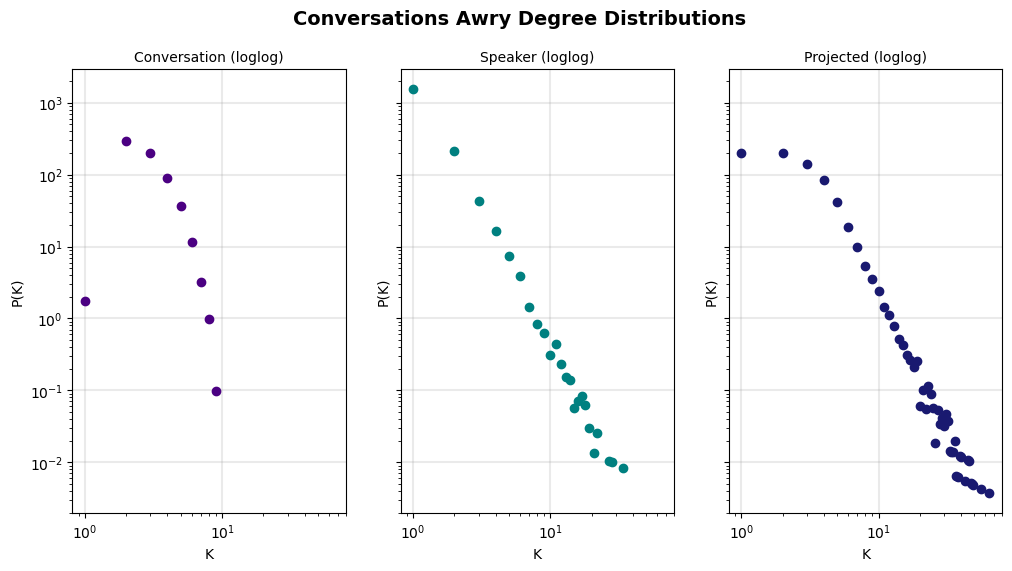

In [95]:
fig, ax = plt.subplots(1,3,figsize=(12,6),dpi=100, sharex=True, sharey=True,)
box_style = dict(facecolor='white', edgecolor='lightgrey', boxstyle='square,pad=0.5', alpha=0.7)

convo_degrees = [wiki_graph.degree(n) for n, attr in wiki_graph.nodes(data=True) if attr.get('bipartite') == 1]
speaker_degrees = [wiki_graph.degree(n) for n, attr in wiki_graph.nodes(data=True) if attr.get('bipartite') == 0]

# Conversation Degree Dist
deg_bins_convo = np.logspace(0, np.log10(np.max(convo_degrees)+1), num=len(convo_degrees))
probs_convo, _ = np.histogram(convo_degrees, bins=deg_bins_convo, density=True)
final_bins_convo = deg_bins_convo[1:] - np.diff(deg_bins_convo)/2.0

ax[0].loglog(final_bins_convo, probs_convo, marker='o',lw=0, c="indigo")
ax[0].set_ylabel(r"P(K)", fontsize='medium')
ax[0].set_xlabel(r"K", fontsize='medium')
ax[0].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[0].set_title(f'Conversation (loglog)', fontsize='medium')  

# Speaker Degree Dist
deg_bins = np.logspace(0, np.log10(np.max(speaker_degrees)+1), num=len(speaker_degrees))
probs, _ = np.histogram(speaker_degrees, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

ax[1].loglog(final_bins, probs, marker='o',lw=0, c="teal")
ax[1].set_ylabel(r"P(K)", fontsize='medium')
ax[1].set_xlabel(r"K", fontsize='medium')
ax[1].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[1].set_title(f'Speaker (loglog)', fontsize='medium')  

# projected graph
projected_dist = list(dict(wiki_projected.degree()).values())
deg_bins_projected = np.logspace(0, np.log10(np.max(projected_dist)+1), num=len(projected_dist))
probs_projected, _ = np.histogram(projected_dist, bins=deg_bins_projected, density=True)
final_bins_projected = deg_bins_projected[1:] - np.diff(deg_bins_projected)/2.0

ax[2].loglog(final_bins_projected, probs_projected, marker='o',lw=0, c="midnightblue")
ax[2].set_ylabel(r"P(K)", fontsize='medium')
ax[2].set_xlabel(r"K", fontsize='medium')
ax[2].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[2].set_title(f'Projected (loglog)', fontsize='medium')  

fig.suptitle('Conversations Awry Degree Distributions ', fontsize=14, fontweight='bold', y=0.95)
plt.subplots_adjust(top=0.85) 


plt.savefig('images/distributions.png', bbox_inches='tight')
plt.show()

In [101]:
def get_filtered_degrees(G, attr_key, attr_val=None):
  degrees = {node: 0 for node in G.nodes()}

  for u, v, data in G.edges(data=True):
    if attr_key in data:
      if attr_val is None or data[attr_key] == attr_val:
        degrees[u] += 1
        degrees[v] += 1 

  return degrees

In [107]:

fighting = get_filtered_degrees(wiki_projected, "has_personal_attack", True)
peaceful = get_filtered_degrees(wiki_projected, "has_personal_attack", False)
fighting_degs = list(fighting.values())
peaceful_degs = list(peaceful.values())

print(fighting_degs)

[0, 7, 1, 0, 2, 3, 2, 1, 8, 0, 7, 0, 0, 1, 0, 1, 0, 2, 0, 2, 4, 0, 0, 1, 1, 8, 3, 0, 0, 3, 7, 5, 0, 1, 6, 1, 2, 0, 1, 0, 3, 2, 6, 4, 18, 1, 2, 0, 1, 1, 2, 16, 2, 1, 0, 25, 0, 0, 1, 8, 1, 2, 1, 4, 0, 4, 1, 0, 6, 4, 0, 0, 2, 2, 2, 2, 2, 0, 0, 3, 3, 3, 0, 3, 7, 3, 3, 28, 2, 5, 1, 0, 0, 0, 2, 2, 2, 2, 4, 20, 0, 0, 5, 2, 0, 1, 1, 0, 2, 13, 1, 3, 1, 1, 1, 0, 1, 3, 1, 8, 3, 0, 5, 2, 0, 1, 1, 0, 2, 2, 3, 0, 0, 0, 8, 1, 0, 0, 0, 2, 2, 2, 5, 2, 2, 2, 0, 1, 7, 0, 0, 2, 1, 0, 3, 0, 3, 15, 3, 0, 8, 3, 3, 0, 3, 6, 1, 2, 3, 0, 2, 0, 3, 2, 2, 0, 3, 2, 2, 0, 1, 1, 0, 0, 4, 15, 0, 0, 0, 2, 3, 2, 9, 0, 1, 0, 15, 0, 1, 1, 1, 0, 0, 2, 3, 1, 0, 0, 0, 0, 1, 1, 0, 3, 4, 3, 3, 1, 1, 0, 2, 9, 1, 3, 6, 10, 3, 0, 2, 2, 4, 5, 2, 0, 1, 2, 0, 1, 1, 2, 3, 0, 2, 2, 0, 0, 0, 0, 0, 4, 4, 5, 2, 1, 0, 0, 2, 2, 0, 0, 3, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 9, 1, 1, 5, 0, 8, 6, 10, 2, 2, 1, 1, 1, 5, 2, 6, 1, 0, 0, 2, 2, 0, 3, 2, 6, 4, 2, 2, 2, 1, 6, 0, 0, 0, 0, 3, 3, 5, 0, 0, 1, 1, 0, 2, 1, 0, 1, 1, 6, 6, 4, 5, 4, 1, 1, 10, 0, 1, 

[1.03178434e+00 0.00000000e+00 0.00000000e+00 7.59078681e-01
 0.00000000e+00 4.01823786e-01 0.00000000e+00 1.62842804e-01
 7.27009104e-02 3.34258606e-02 1.27392626e-02 1.17217141e-02
 4.96130341e-03 2.94741465e-03 1.10945042e-03 7.96249796e-04
 2.53609389e-04 8.40068425e-05 3.47835583e-05]


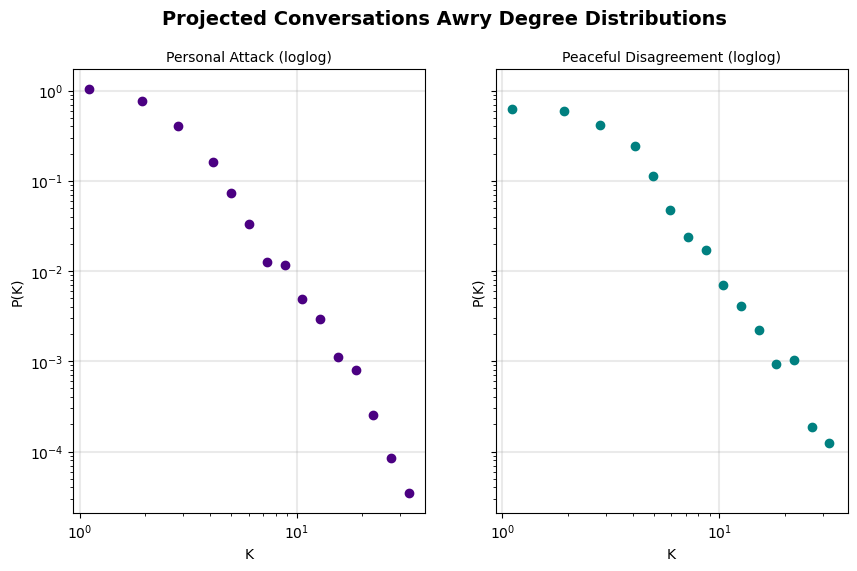

In [111]:
fig, ax = plt.subplots(1,2,figsize=(10,6),dpi=100, sharex=True, sharey=True,)

fighting = get_filtered_degrees(wiki_projected, "has_personal_attack", True)
peaceful = get_filtered_degrees(wiki_projected, "has_personal_attack", False)
fighting_degs = list(fighting.values())
peaceful_degs = list(peaceful.values())

# Fighting Degree Dist
deg_bins_fighting = np.logspace(0, np.log10(np.max(fighting_degs)+1), num=20)
probs_fighting, _ = np.histogram(fighting_degs, bins=deg_bins_fighting, density=True)
final_bins_fighting = deg_bins_fighting[1:] - np.diff(deg_bins_fighting)/2.0

print(probs_fighting)
ax[0].loglog(final_bins_fighting, probs_fighting, marker='o',lw=0, c="indigo")
ax[0].set_ylabel(r"P(K)", fontsize='medium')
ax[0].set_xlabel(r"K", fontsize='medium')
ax[0].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[0].set_title(f'Personal Attack (loglog)', fontsize='medium')  


# Peaceful Degree Dist
deg_bins = np.logspace(0, np.log10(np.max(peaceful_degs)+1), num=20)
probs, _ = np.histogram(peaceful_degs, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

ax[1].loglog(final_bins, probs, marker='o',lw=0, c="teal")
ax[1].set_ylabel(r"P(K)", fontsize='medium')
ax[1].set_xlabel(r"K", fontsize='medium')
ax[1].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[1].set_title(f'Peaceful Disagreement (loglog)', fontsize='medium')  


fig.suptitle('Projected Conversations Awry Degree Distributions ', fontsize=14, fontweight='bold', y=0.95)
plt.subplots_adjust(top=0.85) 


plt.savefig('images/projected_distributions.png', bbox_inches='tight')
plt.show()

#### Connected components?

In [117]:
connected_comps = nx.number_connected_components(wiki_projected)
connected_comps

517

#### Communities?

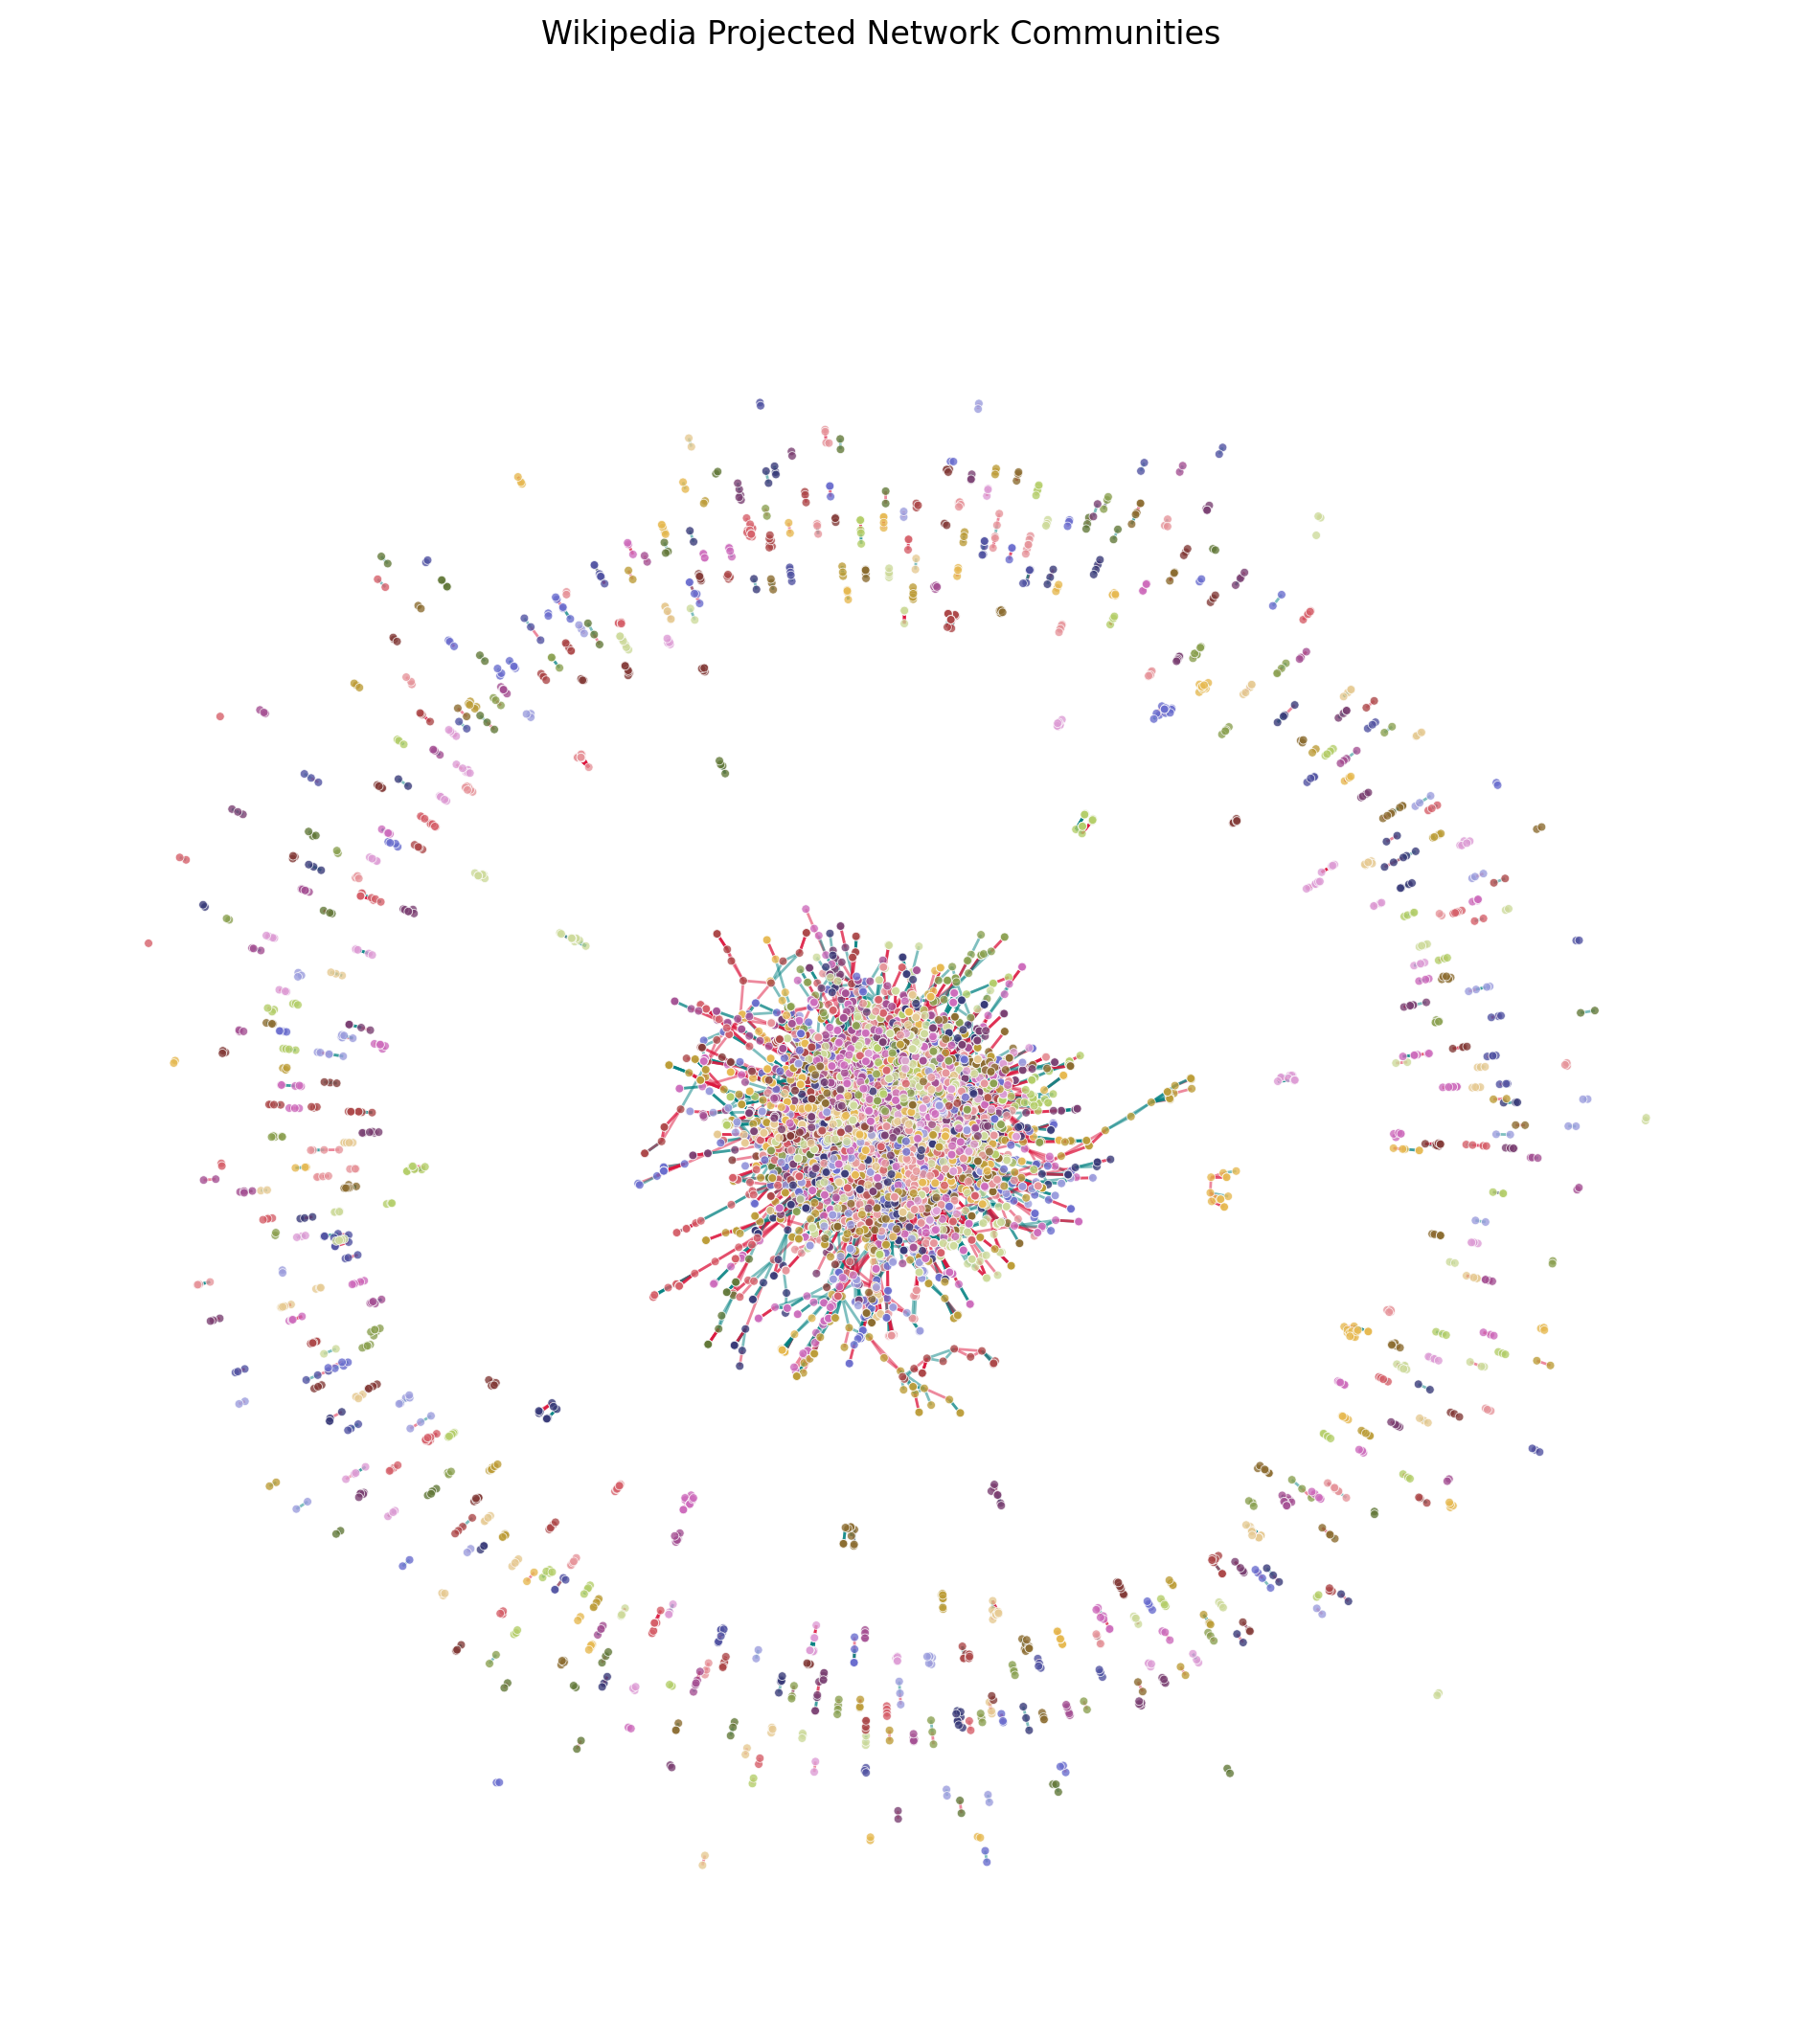

In [118]:
# Look at communities 
communities = nx.community.louvain_communities(wiki_projected, seed=67)

nx_node_dict = {
    node: community_id 
    for community_id, community_nodes in enumerate(communities) 
    for node in community_nodes
}

fig, ax = plt.subplots(1,1,figsize=(12,12),dpi=200)

pos = nx.spring_layout(wiki_projected)
colors_sns = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(communities)))))
colors_nodes = [colors_sns[nx_node_dict[node]] for node in wiki_projected.nodes()]

colors_edges = [
    "crimson" if data["has_personal_attack"] == False else "teal"
    for u, v, data in wiki_projected.edges(data=True)
]

nx.draw_networkx_edges(wiki_projected, pos, width=1, edge_color=colors_edges, alpha=0.5)
nx.draw_networkx_nodes(wiki_projected, pos=pos, node_size=10, node_color=colors_nodes, alpha=0.8,
                       edgecolors='w', linewidths=0.3)



plt.suptitle("Wikipedia Projected Network Communities")
plt.box(False)


plt.savefig("images/projected_communities.png")
plt.show()

#### Now lets just look at largest component

In [130]:
largest_cc_nodes = max(nx.connected_components(wiki_projected), key=len)
wiki_projected_cc = wiki_projected.subgraph(largest_cc_nodes).copy()

In [ ]:
# Look at communities 
communities = nx.community.louvain_communities(wiki_projected_cc, seed=67)

nx_node_dict = {
    node: community_id 
    for community_id, community_nodes in enumerate(communities) 
    for node in community_nodes
}

fig, ax = plt.subplots(1,1,figsize=(12,12),dpi=200)

pos = nx.spring_layout(wiki_projected_cc)
colors_sns = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(communities)))))
colors_nodes = [colors_sns[nx_node_dict[node]] for node in wiki_projected_cc.nodes()]

colors_edges = [
    "crimson" if data["has_personal_attack"] == False else "teal"
    for u, v, data in wiki_projected_cc.edges(data=True)
]

nx.draw_networkx_edges(wiki_projected_cc, pos, width=1, edge_color=colors_edges, alpha=0.5)
nx.draw_networkx_nodes(wiki_projected_cc, pos=pos, node_size=10, node_color=colors_nodes, alpha=0.8,
                       edgecolors='w', linewidths=0.3)



plt.suptitle("Wikipedia Projected - Largest Component")
plt.box(False)


plt.savefig("images/projected_communities_largest_cc.png")
plt.show()

#### Maybe we can do better

KeyError: 'personal_attack_normed'

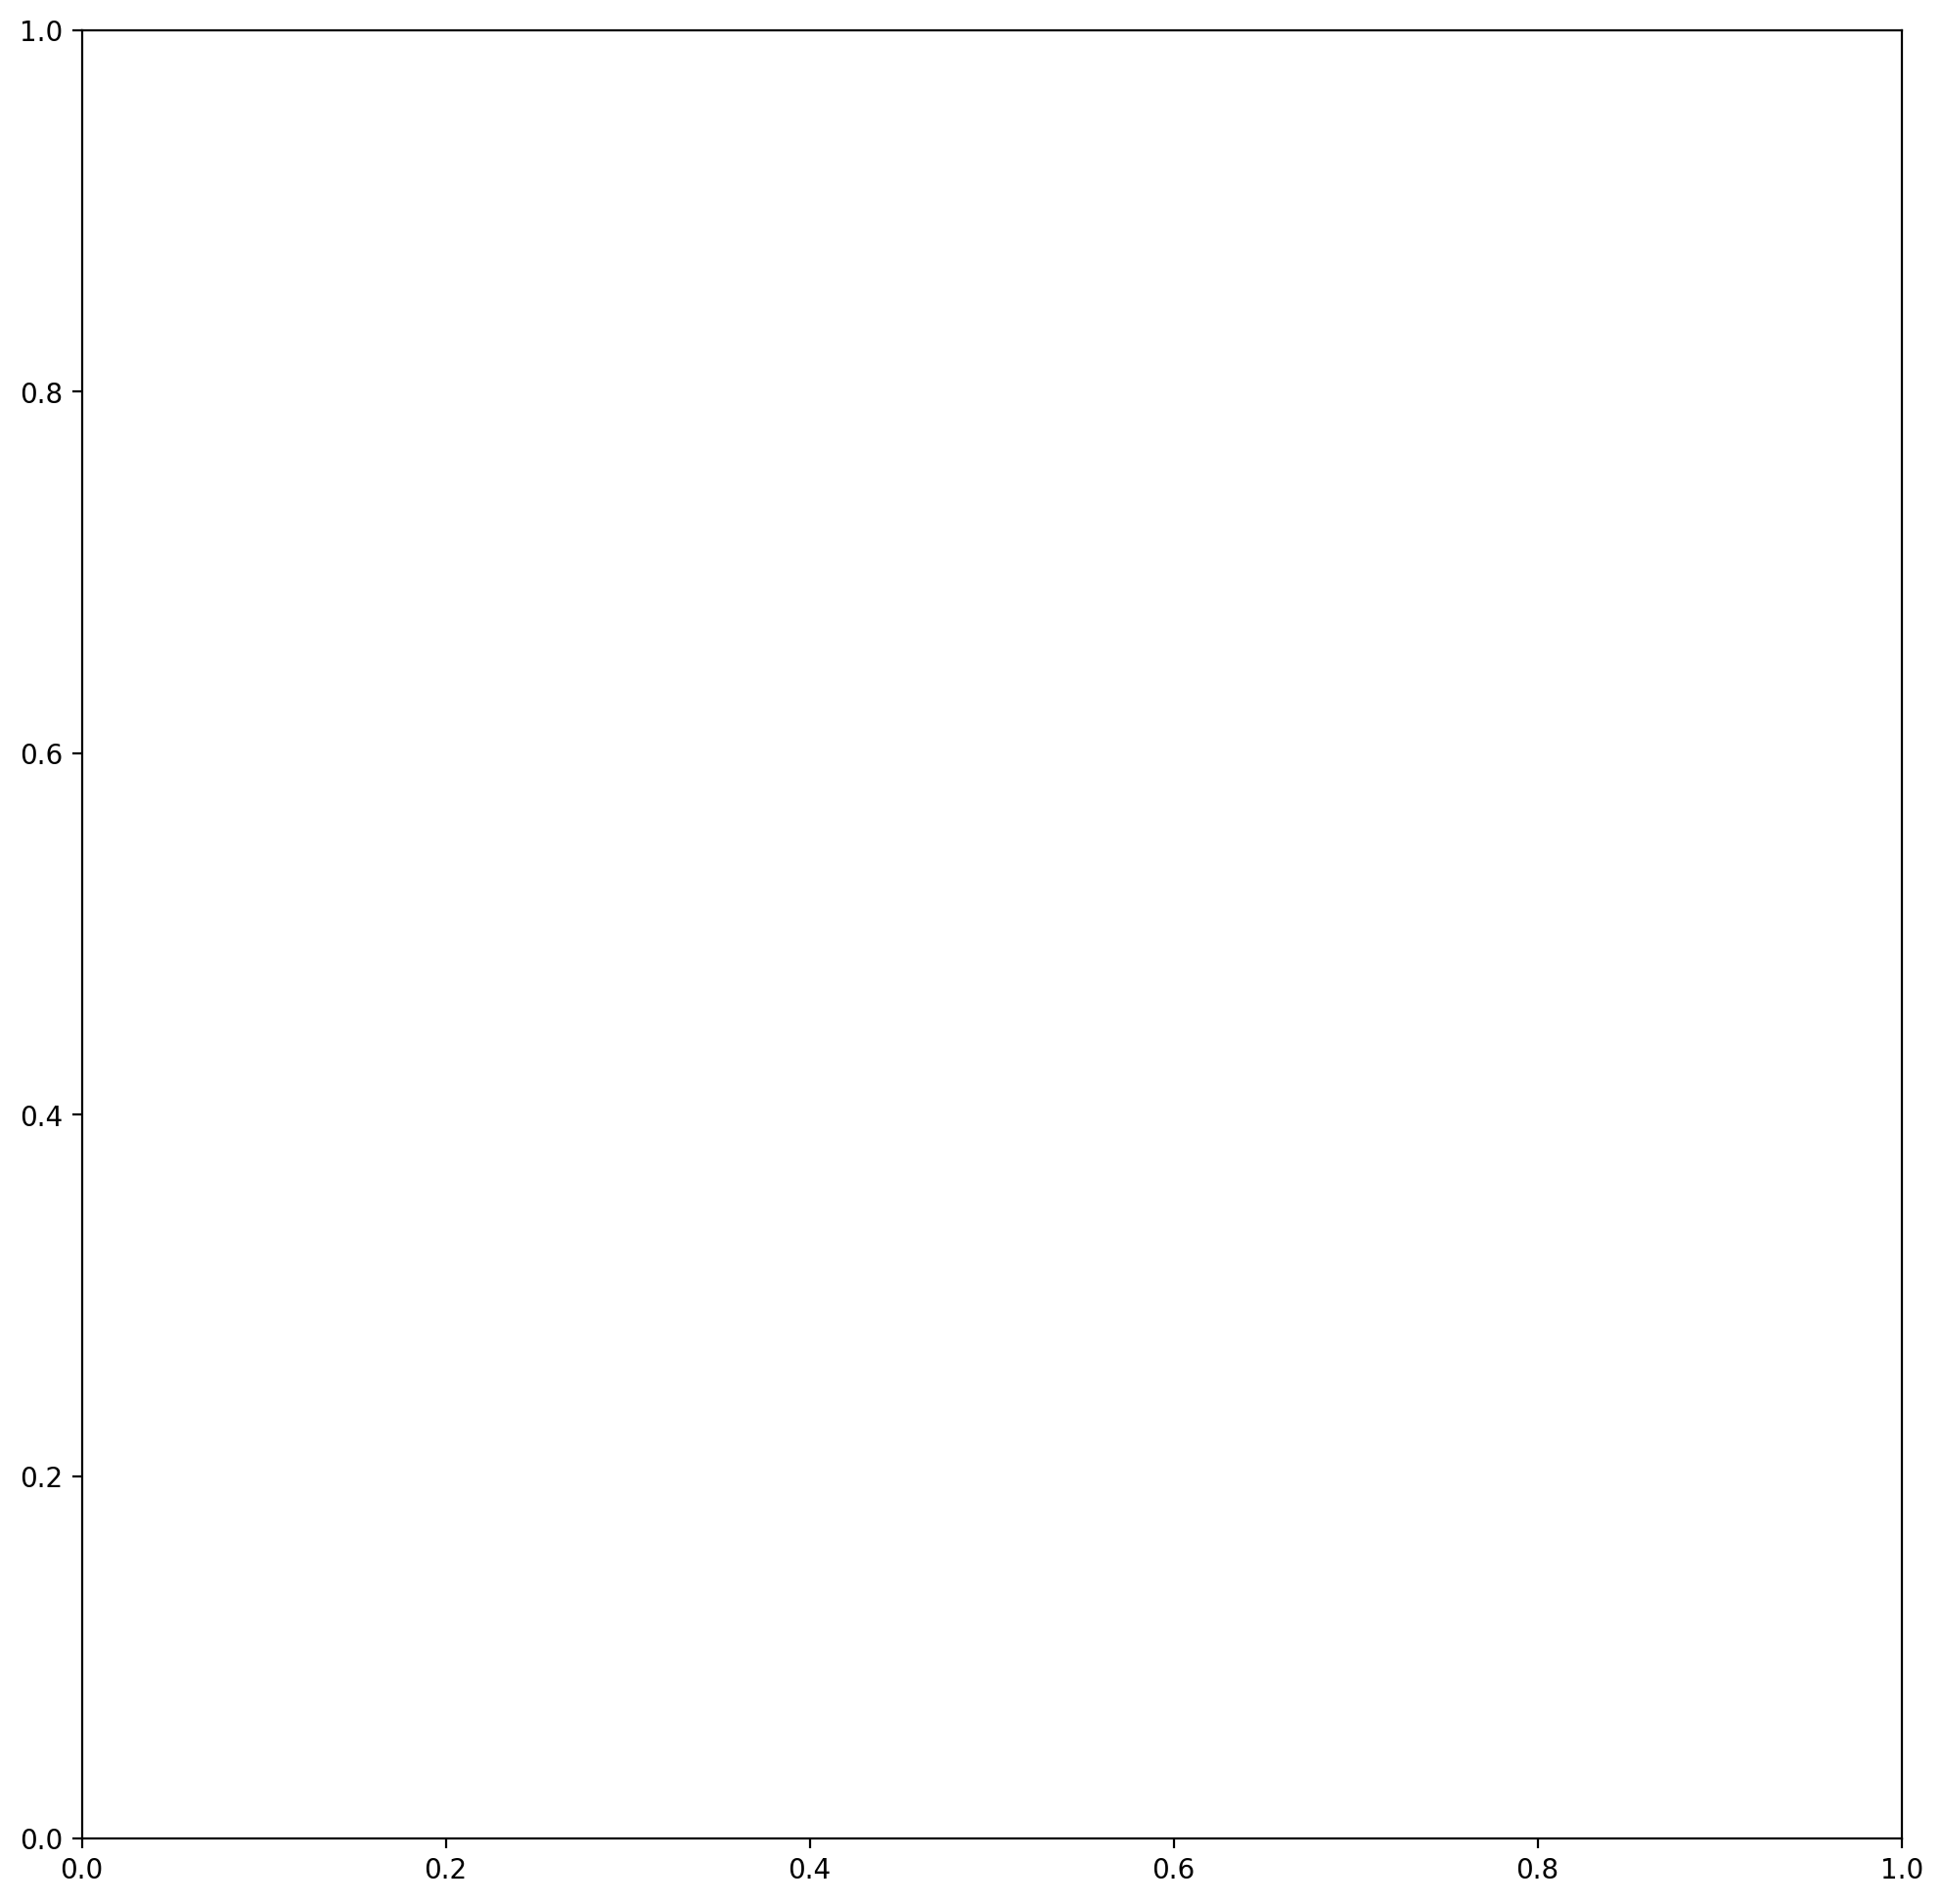

In [129]:
fig, ax = plt.subplots(1,1,figsize=(12,12),dpi=200)

# node colors

# create cmap
spectrum_colors = ["teal", "crimson"] 
cmap = LinearSegmentedColormap.from_list("attack_gradiant", spectrum_colors)

node_colors = []
for el in wiki_projected_cc.nodes(data=True):
    attack_normed = el[1]['personal_attack_normed']
    color = cmap(attack_normed) # normalize it by total degree
    node_colors.append(color)

for u, v, d in wiki_projected.edges(data=True):
    d['layout_weight'] = 2.0 if d['has_personal_attack'] == False else 0.01

pos = nx.spring_layout(wiki_projected_cc, weight='layout_weight', k=2, iterations=100)

pos_edges = [(u, v) for u, v, d in wiki_projected_cc.edges(data=True) if d['has_personal_attack'] == False]
neg_edges = [(u, v) for u, v, d in wiki_projected_cc.edges(data=True) if d['has_personal_attack'] == True]

nx.draw_networkx_nodes(wiki_projected_cc, pos, node_color=node_colors, node_size=10,  edgecolors='w', linewidths=0.3)
nx.draw_networkx_edges(wiki_projected_cc, pos, edgelist=pos_edges, edge_color='teal', width=.3, alpha=0.2)
nx.draw_networkx_edges(wiki_projected_cc, pos, edgelist=neg_edges, edge_color='crimson', width=.3, alpha=0.2)

plt.legend()
plt.show()